# Лабораторная работа № 3. Оптимизация гиперпараметров SVM

Задача — Titanic из лабораторной № 2. Модель — SVC с RBF-ядром.
Критерий поиска — максимальный F1 класса Survived=1.
Сравниваются исходный SVM, GridSearchCV и RandomizedSearchCV при одинаковом бюджете.
Основание: lab03.pdf и preza.pdf. Данные и предобработка сохранены из лабораторной № 2.

## 1. Настройки эксперимента

Используются версии зависимостей лабораторной № 2 (`../classification/requirements.txt`).

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import loguniform
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV, ParameterGrid,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_FOLDS = 5
N_JOBS = 1
RANDOM_ITERATIONS = 32
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})
%matplotlib inline

print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.6.1


## 2. Данные и воспроизводимость baseline

Используется ранее опубликованный `classification/data/titanic.csv`.
Сохранены семь признаков и стратифицированное разбиение лабораторной № 2.

In [2]:
DATA_PATH = Path('../classification/data/titanic.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('classification/data/titanic.csv')
data = pd.read_csv(DATA_PATH)

numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']
feature_columns = numeric_features + categorical_features
X = data[feature_columns].copy()
y = data['Survived'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

assert {'Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'}.isdisjoint(X.columns)
assert X_train.index.intersection(X_test.index).empty
display(pd.DataFrame({
    'N': [len(y_train), len(y_test)],
    'Survived=1': [int(y_train.sum()), int(y_test.sum())],
    'Доля класса 1': [y_train.mean(), y_test.mean()],
}, index=['Train', 'Test']).round(4))

,N,Survived=1,Доля класса 1
Train,712,273,0.3834
Test,179,69,0.3855


Тестовое разбиение уже использовалось в лабораторной № 2: его качество исходной модели известно.
Оно повторно используется как фиксированная сравнительная выборка, а не объявляется новым слепым тестом.
Пространства поиска и правило выбора задаются заранее по смыслу гиперпараметров.
В лабораторной № 3 test не передаётся в подбор и оценивается только после фиксации решения;
параметры по итоговым тестовым результатам не корректируются.

Исходная модель — основной SVM обновлённой лабораторной № 2:
C=10, gamma="scale", class_weight="balanced", kernel="rbf".
Числовые пропуски заполняются медианой train, категории — модой, применяется One-Hot.
Числовые признаки стандартизуются: SVM зависит от расстояний и геометрии.
Все преобразования находятся в Pipeline и заново обучаются в каждом фолде.

In [3]:
BASELINE_PARAMS = {'kernel': 'rbf', 'C': 10, 'gamma': 'scale', 'class_weight': 'balanced'}


def make_model():
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features),
    ])
    return Pipeline([
        ('preprocess', preprocess),
        ('classifier', SVC(**BASELINE_PARAMS)),
    ])


baseline_model = make_model()
display(pd.Series(BASELINE_PARAMS, name='Исходные настройки SVM'))

kernel               rbf
C                     10
gamma              scale
class_weight    balanced
Name: Исходные настройки SVM, dtype: object

## 3. Гиперпараметры и бюджет

| Параметр | Grid | Random | Смысл и ожидаемое влияние |
|---|---|---|---|
| C | 0.1, 1, 10, 100 | log-uniform [0.1, 100] | Штраф за нарушения разделения. Большой C ослабляет регуляризацию и может усилить подгонку |
| gamma | scale, 0.01, 0.1, 1 | те же четыре варианта | Локальность RBF-границы: слишком большое значение может переобучаться, слишком малое — недообучаться |
| class_weight | None, balanced | те же два варианта | balanced повышает вес редкого класса, меняя компромисс Precision/Recall |

RBF-ядро фиксировано. Grid проверяет 4×4×2=32 комбинации.
Random проверяет 32 точки при тех же вариантах gamma и весов, но с непрерывным C внутри общих границ.
Значение gamma="scale" вычисляется из подготовленных обучающих признаков внутри каждого fit.
Изменение class_weight не гарантирует роста F1, поэтому оценивается на CV.

In [4]:
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 0.01, 0.1, 1],
    'classifier__class_weight': [None, 'balanced'],
}
param_distributions = {
    'classifier__C': loguniform(0.1, 100),
    'classifier__gamma': ['scale', 0.01, 0.1, 1],
    'classifier__class_weight': [None, 'balanced'],
}
grid_candidates = len(ParameterGrid(param_grid))
assert grid_candidates == RANDOM_ITERATIONS == 32
print('Grid:', grid_candidates, 'варианта,', grid_candidates * N_FOLDS, 'CV fit')
print('Random:', RANDOM_ITERATIONS, 'варианта,', RANDOM_ITERATIONS * N_FOLDS, 'CV fit')
print('Плюс по одному итоговому refit на train для каждого поиска.')

Grid: 32 варианта, 160 CV fit
Random: 32 варианта, 160 CV fit
Плюс по одному итоговому refit на train для каждого поиска.


## 4. Кросс-валидация и исходное качество

Использованы пять стратифицированных фолдов: компромисс между числом проверок и стоимостью подбора.
В каждом validation около 142–143 пассажиров, доли классов сохранены.
Список индексов фолдов один раз зафиксирован и повторно используется во всех проверках.

In [5]:
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(splitter.split(X_train, y_train))
baseline_cv = cross_validate(
    baseline_model, X_train, y_train, cv=cv_splits,
    scoring='f1', return_train_score=True, n_jobs=N_JOBS,
    error_score='raise',
)
baseline_model.fit(X_train, y_train)
baseline_fold_scores = baseline_cv['test_score']
print(f'Исходный CV F1: {baseline_fold_scores.mean():.4f}')
print(f'Разброс по фолдам: {baseline_fold_scores.std():.4f}')
print('Отдельные фолды:', np.round(baseline_fold_scores, 4))

Исходный CV F1: 0.7667
Разброс по фолдам: 0.0384
Отдельные фолды: [0.8    0.7222 0.8224 0.7544 0.7347]


## 5. Grid Search

Полностью перебирается сетка из 32 комбинаций. Время включает 160 CV fit и один итоговый refit.
Параллелизм одинаков для обеих стратегий: n_jobs=1.

In [6]:
grid_search = GridSearchCV(
    make_model(), param_grid=param_grid, scoring='f1', cv=cv_splits,
    n_jobs=N_JOBS, return_train_score=True, refit=True, error_score='raise',
)
start = perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - start

grid_results = pd.DataFrame(grid_search.cv_results_)
print('Проверено комбинаций:', len(grid_results))
print('Лучшие параметры:', grid_search.best_params_)
print(f'Лучший CV F1: {grid_search.best_score_:.4f}')
print(f'Время Grid Search: {grid_seconds:.2f} с')
display(grid_results[
    ['param_classifier__C', 'param_classifier__gamma',
     'param_classifier__class_weight', 'mean_train_score', 'mean_test_score',
     'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').round(4))

Проверено комбинаций: 32
Лучшие параметры: {'classifier__C': 10, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale'}
Лучший CV F1: 0.7667
Время Grid Search: 2.71 с


,param_classifier__C,param_classifier__gamma,param_classifier__class_weight,mean_train_score,mean_test_score,std_test_score,rank_test_score
20,10.0,scale,balanced,0.8317,0.7667,0.0384,1
25,100.0,0.01,None,0.7725,0.7620,0.0461,2
22,10.0,0.1,balanced,0.8111,0.7594,0.0436,3
29,100.0,0.01,balanced,0.7753,0.7593,0.0457,4
10,1.0,0.1,None,0.7708,0.7543,0.0298,5
12,1.0,scale,balanced,0.7859,0.7492,0.0270,6
15,1.0,1,balanced,0.8447,0.7492,0.0410,7
14,1.0,0.1,balanced,0.7790,0.7489,0.0301,8
18,10.0,0.1,None,0.7943,0.7451,0.0173,9
8,1.0,scale,None,0.7815,0.7447,0.0311,10


## 6. Random Search

Случайный поиск использует 32 комбинации, пять общих фолдов и random_state=42.
Время включает refit. Test не передаётся поиску.

In [7]:
random_search = RandomizedSearchCV(
    make_model(), param_distributions=param_distributions,
    n_iter=RANDOM_ITERATIONS, scoring='f1', cv=cv_splits,
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
    return_train_score=True, refit=True, error_score='raise',
)
start = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - start

random_results = pd.DataFrame(random_search.cv_results_)
print('Проверено комбинаций:', len(random_results))
print('Лучшие параметры:', random_search.best_params_)
print(f'Лучший CV F1: {random_search.best_score_:.4f}')
print(f'Время Random Search: {random_seconds:.2f} с')
display(random_results[
    ['param_classifier__C', 'param_classifier__gamma',
     'param_classifier__class_weight', 'mean_train_score', 'mean_test_score',
     'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').round(4))

Проверено комбинаций: 32
Лучшие параметры: {'classifier__C': 4.366473592979633, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale'}
Лучший CV F1: 0.7606
Время Random Search: 2.58 с


,param_classifier__C,param_classifier__gamma,param_classifier__class_weight,mean_train_score,mean_test_score,std_test_score,rank_test_score
24,4.3665,scale,balanced,0.8171,0.7606,0.0421,1
0,1.3293,0.1,None,0.7756,0.7596,0.0238,2
17,78.8671,0.01,balanced,0.7748,0.7593,0.0457,3
4,6.3584,0.1,balanced,0.8050,0.7570,0.0421,4
27,6.2187,0.1,balanced,0.8042,0.7558,0.0428,5
9,1.9762,0.1,None,0.7806,0.7557,0.0388,6
7,0.3511,scale,None,0.7702,0.7530,0.0421,7
16,0.1567,scale,balanced,0.7601,0.7529,0.0432,8
8,0.8179,scale,balanced,0.7831,0.7523,0.0275,9
30,1.4657,0.1,balanced,0.7815,0.7511,0.0291,10


## 7. Сравнение поисков и фиксация решения

Бюджеты одинаковы по числу комбинаций и фолдов: 160 CV fit плюс один refit на стратегию.
Время зависит от числа опорных векторов, сложности настройки, сходимости решателя и нагрузки.
При равенстве среднего CV выбирается исходная или раньше указанная конфигурация.
Решение фиксируется по CV до итоговой тестовой таблицы.

In [8]:
search_comparison = pd.DataFrame({
    'Комбинаций': [len(grid_results), len(random_results)],
    'CV fit': [len(grid_results) * N_FOLDS, len(random_results) * N_FOLDS],
    'Refit': [1, 1],
    'CV F1': [grid_search.best_score_, random_search.best_score_],
    'Время, с': [grid_seconds, random_seconds],
}, index=['Grid Search', 'Random Search'])
display(search_comparison.round(4))

cv_means = pd.Series({
    'Baseline': baseline_fold_scores.mean(),
    'Grid Search': grid_search.best_score_,
    'Random Search': random_search.best_score_,
})
selected_name = cv_means.idxmax()
models = {
    'Baseline': baseline_model,
    'Grid Search': grid_search.best_estimator_,
    'Random Search': random_search.best_estimator_,
}
final_model = models[selected_name]
print('Основное решение до открытия тестовой таблицы:', selected_name)
print('Его параметры:', {
    key: final_model.get_params()[key] for key in param_grid
})

,Комбинаций,CV fit,Refit,CV F1,"Время, с"
Grid Search,32,160,1,0.7667,2.7062
Random Search,32,160,1,0.7606,2.5773


Основное решение до открытия тестовой таблицы: Baseline
Его параметры: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__class_weight': 'balanced'}


## 8. Влияние гиперпараметров

Для каждого параметра выбран срез сетки при фиксации остальных на Grid best.
Сравниваются средние train и validation F1; полоса — межфолдовое стандартное отклонение.
C показан в логарифмической шкале. Gamma и class_weight представлены категориями:
scale — обучаемое правило вычисления gamma, а не ещё одна фиксированная числовая точка.
Новых fit для графиков не выполняется.

,Значение,mean_train_score,mean_test_score,std_test_score
4,0.1,0.7488,0.7361,0.0396
12,1.0,0.7859,0.7492,0.0270
20,10.0,0.8317,0.7667,0.0384
28,100.0,0.8534,0.7274,0.0124


,Значение,mean_train_score,mean_test_score,std_test_score
20,scale,0.8317,0.7667,0.0384
21,0.01,0.7381,0.7302,0.0301
22,0.1,0.8111,0.7594,0.0436
23,1,0.8704,0.7260,0.0221


,Значение,mean_train_score,mean_test_score,std_test_score
16,None,0.8225,0.7367,0.0144
20,balanced,0.8317,0.7667,0.0384


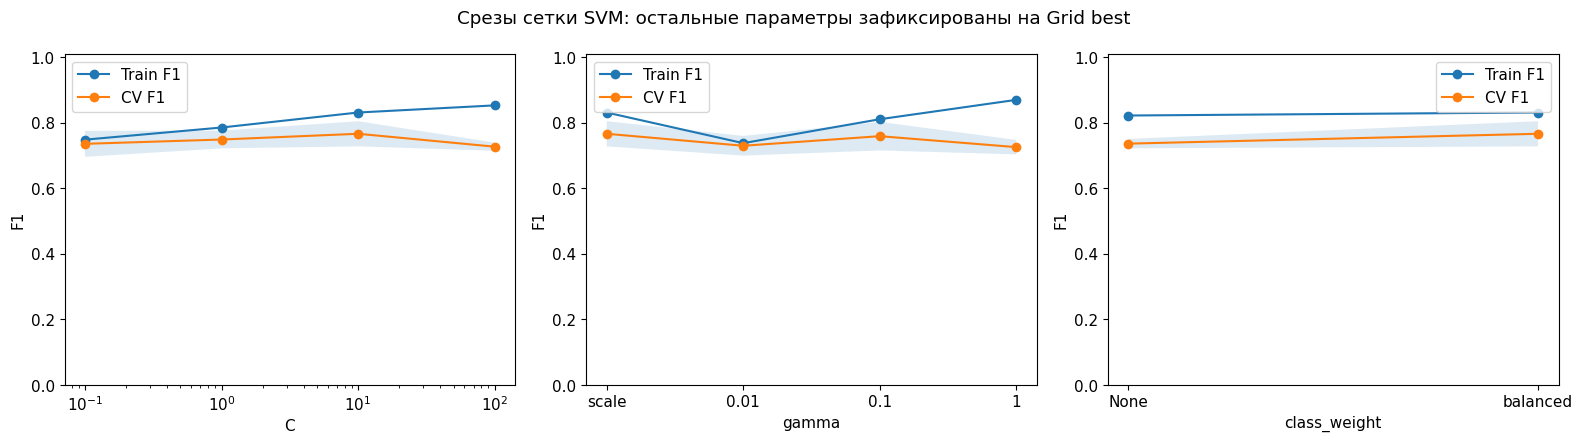

In [9]:
effect_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, parameter in zip(axes, param_grid):
    mask = grid_results['params'].apply(lambda params: all(
        params[key] == value for key, value in grid_search.best_params_.items()
        if key != parameter
    ))
    part = grid_results.loc[mask].copy()
    levels = param_grid[parameter]
    part['Значение'] = part['params'].apply(lambda params: params[parameter])
    part['Порядок'] = part['Значение'].apply(lambda value: levels.index(value))
    part = part.sort_values('Порядок')
    effect_tables[parameter] = part[
        ['Значение', 'mean_train_score', 'mean_test_score', 'std_test_score']
    ]
    validation = part['mean_test_score'].to_numpy()
    spread = part['std_test_score'].to_numpy()
    x_values = np.array(levels) if parameter.endswith('__C') else np.arange(len(levels))
    ax.plot(x_values, part['mean_train_score'], 'o-', label='Train F1')
    ax.plot(x_values, validation, 'o-', label='CV F1')
    ax.fill_between(x_values, validation - spread, validation + spread, alpha=0.15)
    ax.set(xlabel=parameter.split('__')[1], ylabel='F1', ylim=(0, 1.01))
    if parameter.endswith('__C'):
        ax.set_xscale('log')
    else:
        ax.set_xticks(x_values, [str(value) for value in levels])
    ax.legend()
    display(effect_tables[parameter].round(4))
plt.suptitle('Срезы сетки SVM: остальные параметры зафиксированы на Grid best')
plt.tight_layout()
plt.show()

При C=0.1 Train F1=0.7488 близка к CV F1=0.7361: наблюдается относительное недообучение.
При C=10 CV F1 повышается до 0.7667. Дальнейшее увеличение C до 100 повышает Train F1
(0.8317→0.8534), но снижает CV F1 до 0.7274 — признак подгонки.

При gamma=0.01 Train F1=0.7381 и CV F1=0.7302: граница недостаточно гибкая.
При gamma=1 Train F1=0.8704, CV F1=0.7260: высокая локальность даёт большой train–CV-разрыв.
Режим scale в этом срезе обеспечивает CV F1=0.7667.

При фиксированных C=10 и gamma=scale balanced повышает CV F1 с 0.7367 до 0.7667.
Это наблюдаемый эффект выбора весов для данной задачи и метрики, а не гарантия для любых данных.

## 9. Устойчивость по фолдам

Сопоставлены результаты одних и тех же пяти validation-фолдов.
Приведены среднее, стандартное отклонение, минимум и максимум.

,Baseline,Grid Search,Random Search
Fold 1,0.8000,0.8000,0.7890
Fold 2,0.7222,0.7222,0.7407
Fold 3,0.8224,0.8224,0.8288
Fold 4,0.7544,0.7544,0.7288
Fold 5,0.7347,0.7347,0.7158


,CV mean,CV std,Минимум,Максимум
Baseline,0.7667,0.0384,0.7222,0.8224
Grid Search,0.7667,0.0384,0.7222,0.8224
Random Search,0.7606,0.0421,0.7158,0.8288


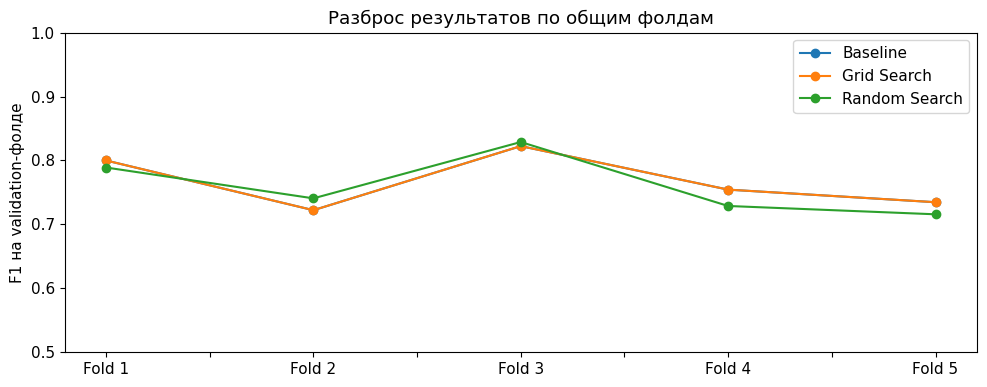

In [10]:
fold_columns = [f'split{i}_test_score' for i in range(N_FOLDS)]
fold_scores = pd.DataFrame({
    'Baseline': baseline_fold_scores,
    'Grid Search': grid_results.loc[grid_search.best_index_, fold_columns].astype(float).to_numpy(),
    'Random Search': random_results.loc[random_search.best_index_, fold_columns].astype(float).to_numpy(),
}, index=[f'Fold {i + 1}' for i in range(N_FOLDS)])
stability = pd.DataFrame({
    'CV mean': fold_scores.mean(),
    'CV std': fold_scores.std(ddof=0),
    'Минимум': fold_scores.min(),
    'Максимум': fold_scores.max(),
})
display(fold_scores.round(4))
display(stability.round(4))
fold_scores.plot(marker='o', ylim=(0.5, 1), figsize=(10, 4))
plt.ylabel('F1 на validation-фолде')
plt.title('Разброс результатов по общим фолдам')
plt.tight_layout()
plt.show()

Grid выбрал ту же конфигурацию, что baseline, поэтому их результаты всех пяти фолдов совпадают.
Среднее CV F1=0.7667, std=0.0384, диапазон 0.7222–0.8224.
У Random среднее ниже (0.7606), разброс немного выше (std=0.0421), диапазон 0.7158–0.8288.
Меньшая вариативность и более высокое среднее поддерживают сохранение исходной конфигурации.
По пяти фолдам различие не объявляется статистически доказанным.

## 10. Итоговая проверка на фиксированном test

После завершения обоих поисков, диагностики и фиксации основного решения
рассчитаны тестовые метрики исходной модели и двух оптимизированных вариантов.
Все три Pipeline уже обучены на полном train. Test не используется для изменения победителя.

,CV F1,CV std,Test Accuracy,Test Precision,Test Recall,Test F1,Изменение CV F1,Изменение Test F1
Модель,,,,,,,,
Baseline,0.7667,0.0384,0.7821,0.7083,0.7391,0.7234,0.0000,0.0000
Grid Search,0.7667,0.0384,0.7821,0.7083,0.7391,0.7234,0.0000,0.0000
Random Search,0.7606,0.0421,0.7933,0.7162,0.7681,0.7413,-0.0061,0.0179


Зафиксированный до теста выбор: Baseline
Его Test F1: 0.7234


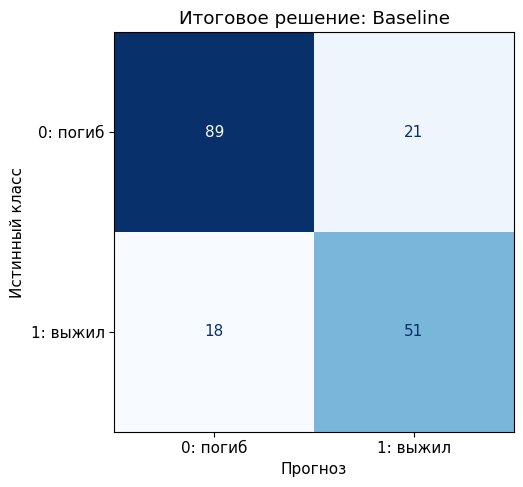

In [11]:
test_predictions = {}
rows = []
for name, fitted_model in models.items():
    prediction = fitted_model.predict(X_test)
    test_predictions[name] = prediction
    rows.append({
        'Модель': name,
        'CV F1': cv_means[name],
        'CV std': stability.loc[name, 'CV std'],
        'Test Accuracy': accuracy_score(y_test, prediction),
        'Test Precision': precision_score(y_test, prediction, zero_division=0),
        'Test Recall': recall_score(y_test, prediction, zero_division=0),
        'Test F1': f1_score(y_test, prediction, pos_label=1),
    })
comparison = pd.DataFrame(rows).set_index('Модель')
comparison['Изменение CV F1'] = comparison['CV F1'] - comparison.loc['Baseline', 'CV F1']
comparison['Изменение Test F1'] = comparison['Test F1'] - comparison.loc['Baseline', 'Test F1']
display(comparison.round(4))

y_pred = test_predictions[selected_name]
print('Зафиксированный до теста выбор:', selected_name)
print(f"Его Test F1: {comparison.loc[selected_name, 'Test F1']:.4f}")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['0: погиб', '1: выжил'],
    cmap='Blues', colorbar=False,
)
plt.title(f'Итоговое решение: {selected_name}')
plt.xlabel('Прогноз')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

## 11. Заключение

Оптимизированы C, gamma и class_weight у SVM с RBF-ядром из обновлённой лабораторной № 2.
Оба поиска проверили по 32 конфигурации на пяти одинаковых фолдах — по 160 CV fit и одному refit.

| Вариант | CV F1 | Test F1 | Изменение CV | Изменение test |
|---|---:|---:|---:|---:|
| Исходный SVM | 0.7667 | 0.7234 | — | — |
| Grid Search | 0.7667 | 0.7234 | 0.0000 | 0.0000 |
| Random Search | 0.7606 | 0.7413 | −0.0061 | +0.0179 |

Grid подтвердил исходные настройки C=10, gamma="scale", class_weight="balanced".
Random выбрал C≈4.36647 при тех же gamma и весах. По CV он уступил baseline.
По заранее зафиксированному правилу равенства основной моделью остался **исходный SVM**,
эквивалентный победителю Grid; его Test F1=0.7234.

На test вариант Random оказался выше, но его преимущество не использовалось для изменения решения.
CV и test оценивают разные конечные группы пассажиров; отбор максимума CV также вносит оптимизм.
Поиск не гарантирует улучшение уже сильной конфигурации: здесь он подтвердил её пригодность.
Срезы показывают ухудшение переноса при слишком большом C и gamma и полезность весов balanced для F1.
Реальные времена поиска приведены в разделе 7 и могут отличаться при повторном запуске.

Test уже использовался в предыдущих версиях работ и является сравнительным, а не новым слепым набором.
После тестовой таблицы настройки не изменялись. Скрытая проверка преподавателя недоступна.